In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from collections import Counter

# 1. Unduh dan Import Dataset

In [2]:
df = pd.read_excel('Online Retail.xlsx')
print('Shape:', df.shape)
df.head()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


# 2. Eksplorasi dan Pembersihan Data

In [4]:
missing = pd.DataFrame({
    'count' : df.isna().sum(),
    'percentage' : (df.isna().mean()*100).round(1),
}).sort_values('count', ascending=False)
missing[missing['count'] > 0]

,count,percentage
CustomerID,135080,24.9
Description,1454,0.3


In [5]:
# Kolom yang relevan untuk pola berurutan:
# CustomerID (siapa), InvoiceDate (kapan), InvoiceNo (transaksi), Description (produk)
print('Jumlah invoice unik:', df['InvoiceNo'].nunique())
print('Jumlah pelanggan unik:', df['CustomerID'].nunique())
print('Jumlah produk unik:', df['Description'].nunique())
print('Baris transaksi batal (InvoiceNo diawali C):', df['InvoiceNo'].astype(str).str.startswith('C').sum())
print('Baris dengan Quantity <= 0:', (df['Quantity'] <= 0).sum())
print('Baris dengan CustomerID kosong:', df['CustomerID'].isna().sum())

Jumlah invoice unik: 25900
Jumlah pelanggan unik: 4372
Jumlah produk unik: 4223
Baris transaksi batal (InvoiceNo diawali C): 9288
Baris dengan Quantity <= 0: 10624
Baris dengan CustomerID kosong: 135080


In [6]:
# Pembersihan data, jumlah baris, invoice, dan pelanggan dicatat di setiap langkah
tahap = {'Awal': df}

df_clean = df.dropna(subset=['Description'])
tahap['Hapus Description kosong'] = df_clean

df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
tahap['Hapus transaksi batal (C)'] = df_clean

df_clean = df_clean[df_clean['Quantity'] > 0]
tahap['Hapus Quantity <= 0'] = df_clean

df_clean = df_clean.dropna(subset=['CustomerID']).copy()
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
tahap['Hapus CustomerID kosong'] = df_clean

# Rapikan spasi di Description (spasi ganda dan spasi di ujung),
# lalu hapus baris yang bukan produk (ongkos kirim dan input manual)
df_clean['Description'] = df_clean['Description'].str.replace(r'\s+', ' ', regex=True).str.strip()
non_produk = ['POSTAGE', 'DOTCOM POSTAGE', 'CARRIAGE', 'Manual']
df_clean = df_clean[~df_clean['Description'].isin(non_produk)]
tahap['Hapus item non-produk'] = df_clean

ringkasan = pd.DataFrame({nama: {'Baris': len(d),
                                 'Invoice': d['InvoiceNo'].nunique(),
                                 'Pelanggan': d['CustomerID'].nunique()} for nama, d in tahap.items()}).T
ringkasan

,Baris,Invoice,Pelanggan
Awal,541909,25900,4372
Hapus Description kosong,540455,24446,4372
Hapus transaksi batal (C),531167,20610,4339
Hapus Quantity <= 0,530693,20136,4339
Hapus CustomerID kosong,397924,18536,4339
Hapus item non-produk,396386,18416,4336


count    4336.0
mean        4.2
std         7.6
min         1.0
25%         1.0
50%         2.0
75%         5.0
max       206.0
Name: InvoiceNo, dtype: float64
Pelanggan dengan 1 invoice saja: 1506


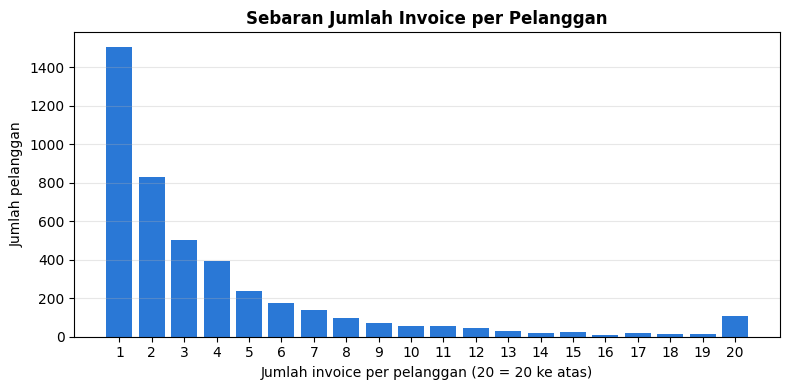

In [7]:
# Banyaknya invoice per pelanggan (nanti menjadi panjang sequence tiap pelanggan)
invoice_per_pelanggan = df_clean.groupby('CustomerID')['InvoiceNo'].nunique()
print(invoice_per_pelanggan.describe().round(1))
print('Pelanggan dengan 1 invoice saja:', (invoice_per_pelanggan == 1).sum())

jumlah = invoice_per_pelanggan.clip(upper=20).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(jumlah.index, jumlah.values, color='#2a78d6')
ax.set_xticks(range(1, 21))
ax.set_xlabel('Jumlah invoice per pelanggan (20 = 20 ke atas)')
ax.set_ylabel('Jumlah pelanggan')
ax.set_title('Sebaran Jumlah Invoice per Pelanggan', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Persiapan Data untuk Sequential Pattern Mining

In [8]:
# Urutkan berdasarkan pelanggan dan waktu,
# lalu satu invoice = satu itemset (daftar produk unik di invoice tersebut)
df_urut = df_clean.sort_values(['CustomerID', 'InvoiceDate'])
itemset = (df_urut.groupby(['CustomerID', 'InvoiceNo'], sort=False)
                  .agg(InvoiceDate=('InvoiceDate', 'first'),
                       Produk=('Description', lambda x: sorted(set(x))))
                  .reset_index())
print('Jumlah itemset (invoice):', len(itemset))
itemset.head()

Jumlah itemset (invoice): 18416


,CustomerID,InvoiceNo,InvoiceDate,Produk
0,12346,541431,2011-01-18 10:01:00,[MEDIUM CERAMIC TOP STORAGE JAR]
1,12347,537626,2010-12-07 14:57:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VIN..."
2,12347,542237,2011-01-26 14:30:00,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIR..."
3,12347,549222,2011-04-07 10:43:00,"[3D SHEET OF CAT STICKERS, 3D SHEET OF DOG STI..."
4,12347,556201,2011-06-09 13:01:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VIN..."


In [9]:
# Satu pelanggan = satu sequence, isinya daftar itemset yang urut dari invoice paling awal
sequence = itemset.groupby('CustomerID')['Produk'].apply(list)
sequences = sequence.tolist()   # list of list, siap diproses PrefixSpan

print('Jumlah sequence (pelanggan):', len(sequences))
print('Rata-rata itemset per sequence: %.1f' % sequence.apply(len).mean())

Jumlah sequence (pelanggan): 4336
Rata-rata itemset per sequence: 4.2


In [10]:
# Contoh satu sequence: pelanggan 12347 (ditampilkan 3 produk pertama di tiap invoice)
for i, produk in enumerate(sequence[12347], 1):
    print(f'Invoice ke-{i}:', produk[:3], '...')

Invoice ke-1: ['3D DOG PICTURE PLAYING CARDS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'ALARM CLOCK BAKELIKE CHOCOLATE'] ...
Invoice ke-2: ['3D DOG PICTURE PLAYING CARDS', '60 TEATIME FAIRY CAKE CASES', '72 SWEETHEART FAIRY CAKE CASES'] ...
Invoice ke-3: ['3D SHEET OF CAT STICKERS', '3D SHEET OF DOG STICKERS', 'AIRLINE BAG VINTAGE JET SET BROWN'] ...
Invoice ke-4: ['3D DOG PICTURE PLAYING CARDS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'AIRLINE BAG VINTAGE TOKYO 78'] ...
Invoice ke-5: ['3D DOG PICTURE PLAYING CARDS', '60 TEATIME FAIRY CAKE CASES', '72 SWEETHEART FAIRY CAKE CASES'] ...
Invoice ke-6: ['3D DOG PICTURE PLAYING CARDS', '60 TEATIME FAIRY CAKE CASES', '72 SWEETHEART FAIRY CAKE CASES'] ...
Invoice ke-7: ['BICYCLE PUNCTURE REPAIR KIT', 'BOOM BOX SPEAKER BOYS', 'CHRISTMAS TABLE SILVER CANDLE SPIKE'] ...


# 4. Penerapan Algoritma (PrefixSpan)

Pola: **A → B → C** = beli A, lalu di invoice berikutnya beli B, lalu C.
- **Support** = pelanggan yang punya pola / semua pelanggan
- **Confidence (A → B)** = support(A → B) / support(A)

In [11]:
def prefixspan(sequences, min_support):
    db = [[set(produk) for produk in seq] for seq in sequences]   # set supaya pencarian produk cepat
    n = len(db)
    hasil = {}   # pola (tuple produk) -> jumlah pelanggan

    def cari(prefix, proyeksi):
        # proyeksi = daftar (nomor pelanggan, posisi invoice tempat pencarian dilanjutkan)

        # 1. Hitung berapa pelanggan yang membeli tiap produk di sisa sequence-nya
        hitung = Counter()
        for c, i in proyeksi:
            hitung.update(set().union(*db[c][i:]))

        # 2. Produk yang support-nya cukup disambungkan ke prefix
        for produk, jumlah in hitung.items():
            if jumlah / n >= min_support:
                pola = prefix + (produk,)
                hasil[pola] = jumlah

                # 3. Proyeksi baru: lanjut dari invoice setelah produk ini pertama kali dibeli
                proyeksi_baru = []
                for c, i in proyeksi:
                    for j in range(i, len(db[c])):
                        if produk in db[c][j]:
                            proyeksi_baru.append((c, j + 1))
                            break
                cari(pola, proyeksi_baru)

    cari((), [(c, 0) for c in range(n)])
    return hasil

In [12]:
n_pelanggan = len(sequences)

def ke_tabel(hasil):
    # Ambil pola minimal 2 langkah (pola 1 langkah hanya produk yang sering dibeli), lalu hitung support dan confidence
    baris = []
    for urutan, jumlah in hasil.items():
        if len(urutan) >= 2:
            baris.append({'pola': ' → '.join(urutan),
                          'panjang': len(urutan),
                          'jumlah_pelanggan': jumlah,
                          'support': jumlah / n_pelanggan,
                          'confidence': jumlah / hasil[urutan[:-1]],
                          'produk_sama': len(set(urutan)) == 1})
    return pd.DataFrame(baris).sort_values(['support', 'confidence'], ascending=False).reset_index(drop=True)

In [13]:
# Titik awal: min_support 0.01 (relatif terhadap jumlah pelanggan), butuh sekitar 40 detik
hasil_awal = prefixspan(sequences, min_support=0.01)
pola_awal = ke_tabel(hasil_awal)

print('Minimal pelanggan per pola:', int(np.ceil(0.01 * n_pelanggan)), 'dari', n_pelanggan)
print('Jumlah pola berurutan:', len(pola_awal))
print('Pola dengan support < 0.015: %d (%.0f%%)' % ((pola_awal['support'] < 0.015).sum(), (pola_awal['support'] < 0.015).mean() * 100))
pola_awal['panjang'].value_counts().sort_index()

Minimal pelanggan per pola: 44 dari 4336
Jumlah pola berurutan: 45303
Pola dengan support < 0.015: 38628 (85%)


panjang
2    15686
3    17479
4    11179
5      949
6        8
7        2
Name: count, dtype: int64

In [14]:
# Jumlah pola untuk beberapa min_support
# (cukup disaring dari hasil 0.01, karena pola yang lolos support lebih besar pasti juga lolos 0.01)
jumlah = []
for sup in [0.01, 0.015, 0.02, 0.03, 0.04, 0.05]:
    p = pola_awal[pola_awal['support'] >= sup]
    jumlah.append({'min_support': sup,
                   'min_pelanggan': int(np.ceil(sup * n_pelanggan)),
                   'jumlah_pola': len(p),
                   'panjang_2': (p['panjang'] == 2).sum(),
                   'panjang_3_ke_atas': (p['panjang'] >= 3).sum(),
                   'produk_berbeda': (~p['produk_sama']).sum()})
pd.DataFrame(jumlah)

,min_support,min_pelanggan,jumlah_pola,panjang_2,panjang_3_ke_atas,produk_berbeda
0,0.010,44,45303,15686,29617,44757
1,0.015,66,6675,4081,2594,6410
2,0.020,87,1973,1514,459,1811
3,0.030,131,294,283,11,228
4,0.040,174,59,57,2,33
5,0.050,217,10,9,1,0


**Penyesuaian min_support**

0.01 → 45.303 pola, terlalu banyak (85% support-nya < 0.015). Dipakai **0.03** → 294 pola. 0.05 hanya 10 pola, semuanya pembelian ulang produk yang sama.

In [15]:
# Nilai yang dipakai: min_support 0.03
hasil = prefixspan(sequences, min_support=0.03)
pola = ke_tabel(hasil)
print('Jumlah pola berurutan:', len(pola))

Jumlah pola berurutan: 294


# 5. Evaluasi Pola Berurutan

In [16]:
# Semua pola beserta support dan confidence (urut dari support tertinggi)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_colwidth', None)
pola[['pola', 'panjang', 'jumlah_pelanggan', 'support', 'confidence']].round(3)

,pola,panjang,jumlah_pelanggan,support,confidence
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,2,405,0.093,0.473
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,2,330,0.076,0.375
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,2,312,0.072,0.491
3,ASSORTED COLOUR BIRD ORNAMENT → ASSORTED COLOUR BIRD ORNAMENT,2,291,0.067,0.429
4,PARTY BUNTING → PARTY BUNTING,2,280,0.065,0.395
5,LUNCH BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,2,276,0.064,0.519
6,LUNCH BAG BLACK SKULL. → LUNCH BAG BLACK SKULL.,2,229,0.053,0.500
7,LUNCH BAG SUKI DESIGN → LUNCH BAG SUKI DESIGN,2,226,0.052,0.521
8,SET OF 3 CAKE TINS PANTRY DESIGN → SET OF 3 CAKE TINS PANTRY DESIGN,2,225,0.052,0.352
9,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,3,222,0.051,0.548


In [17]:
# Ringkasan metrik dan jumlah pola per panjang
print(pola['panjang'].value_counts().sort_index())
pola[['support', 'confidence']].describe().round(3)

panjang
2    283
3     10
4      1
Name: count, dtype: int64


,support,confidence
count,294.000,294.000
mean,0.037,0.336
std,0.007,0.104
min,0.030,0.149
25%,0.032,0.246
50%,0.035,0.346
75%,0.039,0.402
max,0.093,0.670


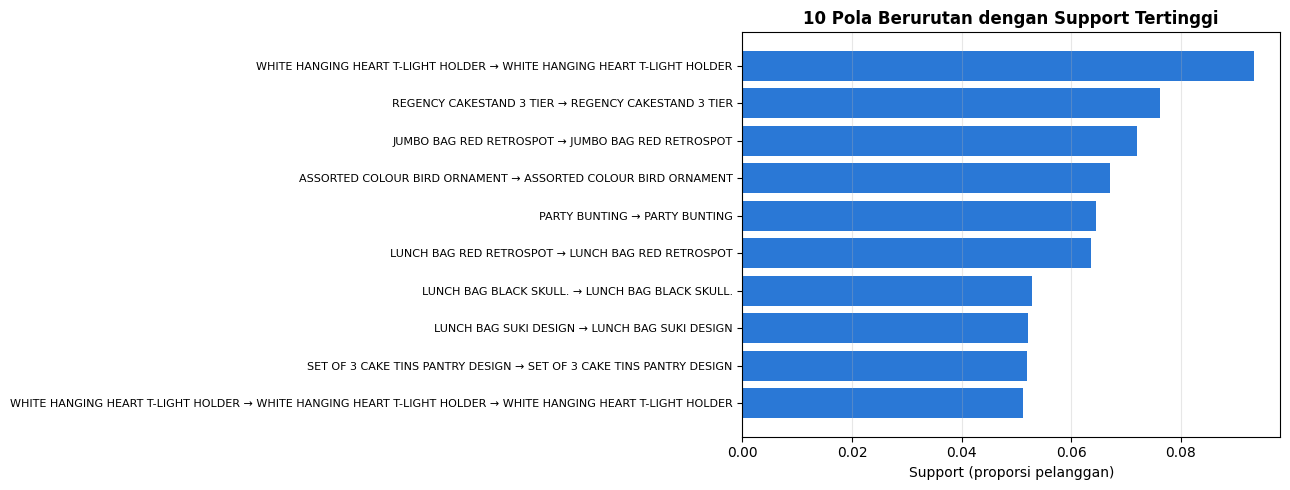

In [18]:
# 10 pola dengan support tertinggi
top10 = pola.head(10)

fig, ax = plt.subplots(figsize=(13, 5))
ax.barh(top10['pola'][::-1], top10['support'][::-1], color='#2a78d6')
ax.set_xlabel('Support (proporsi pelanggan)')
ax.set_title('10 Pola Berurutan dengan Support Tertinggi', fontsize=12, fontweight='bold')
ax.tick_params(axis='y', labelsize=8)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

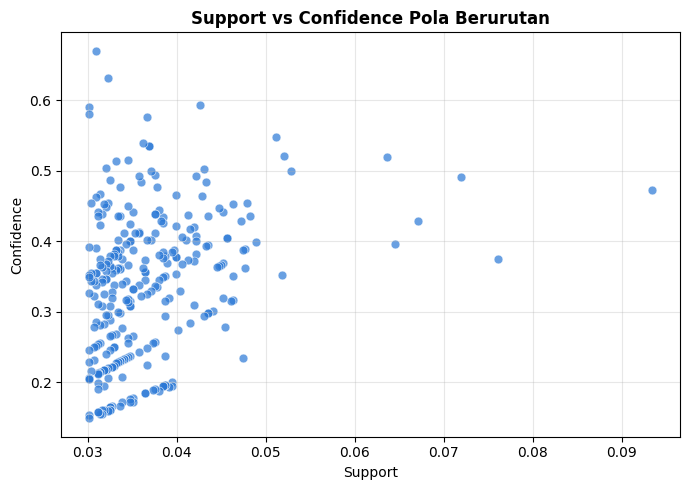

In [19]:
# Sebaran pola: support vs confidence
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(pola['support'], pola['confidence'], color='#2a78d6', s=40, alpha=0.7, edgecolors='white', linewidths=0.5)
ax.set_xlabel('Support')
ax.set_ylabel('Confidence')
ax.set_title('Support vs Confidence Pola Berurutan', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Tiga pola terbaik berdasarkan support tertinggi
top3 = pola.sort_values('support', ascending=False).head(3)
top3[['pola', 'jumlah_pelanggan', 'support', 'confidence']].round(3)

,pola,jumlah_pelanggan,support,confidence
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,405,0.093,0.473
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,330,0.076,0.375
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,312,0.072,0.491


**Interpretasi tiga pola terbaik (support tertinggi)**

1. **WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER**: 405 pelanggan (9,3%) membeli lagi, confidence 47%. Jaga stok dan kirim pengingat "beli lagi".
2. **REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER**: 330 pelanggan (7,6%), confidence 37,5%. Cocok diberi harga grosir atau diskon pembelian ulang.
3. **JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT**: 312 pelanggan (7,2%), confidence 49%. Cocok untuk paket grosir dan pengingat stok ulang.

Ketiganya pembelian ulang produk yang sama.

In [21]:
# Sebagai pelengkap: pola dengan support tertinggi yang isinya produk berbeda
pola[~pola['produk_sama']].head(5)[['pola', 'jumlah_pelanggan', 'support', 'confidence']].round(3)

,pola,jumlah_pelanggan,support,confidence
10,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,212,0.049,0.398
11,LUNCH BAG CARS BLUE → LUNCH BAG RED RETROSPOT,209,0.048,0.436
12,LUNCH BAG BLACK SKULL. → LUNCH BAG RED RETROSPOT,208,0.048,0.454
13,LUNCH BAG RED RETROSPOT → LUNCH BAG SPACEBOY DESIGN,207,0.048,0.389
15,LUNCH BAG RED RETROSPOT → LUNCH BAG SUKI DESIGN,206,0.048,0.387


Pola produk berbeda didominasi seri **LUNCH BAG** → rekomendasikan motif lain dari seri yang sama setelah pembelian pertama.

# 6. Kesimpulan

- 4.336 pelanggan disusun menjadi sequence, rata-rata 4,2 invoice per pelanggan.
- min_support 0.03 menghasilkan 294 pola berurutan.
- Pola paling umum: pembelian ulang produk laris (confidence 37–49%).
- Pola produk berbeda berasal dari satu seri produk (LUNCH BAG, JUMBO BAG).